# Feature Selection (Seed 42) on the Corrected 561-Sample Dataset

This notebook performs feature selection on the current curated no-BO dataset using descriptors that do not require EIS circuit fitting.

The workflow rebuilds the electrochemical inputs from `data_extraction/all_data`, estimates `Rs_from_EIS` directly from high-frequency EIS real impedance, extracts `I_raw` from LSV at -1.0 V, calculates Et-derived potentials, applies the same potential-dependent shifts to selected metal descriptors, and then performs backward elimination.

Candidate features are restricted to:

- raw electrochemical descriptors: `I_raw`, `Rs_from_EIS`
- metal/property descriptors expanded as `element1` and `element2`

The old EIS-fitting descriptors (`Rct_log`, `Cp_log`, `Rp_log`, `C_dl_log`, `tafel_slope`, `W_sigma_log`) are not generated and are not used.

Outputs are written to `outputs/feature_selection_561_rs_from_eis_no_eis_fitting_seed42`.

LSV geometry note: `Ag-Ce`, `Co-V`, and `Mo-Mg` were measured with a 2 cm2 geometry. The notebook reads `data_extraction/all_data/LSV/lsv_geometry_area_metadata.csv` and area-normalizes `I_raw` to the standard 1 cm2 convention during feature construction. For eta10 extraction from those raw LSV curves, the comparable value is raw eta20.



In [1]:
from pathlib import Path
import os


def find_repo_root(start=None):
    path = Path.cwd() if start is None else Path(start)
    for candidate in [path, *path.parents]:
        if (candidate / "hd_separation_ml").exists() and (candidate / "0-Figures").exists():
            return candidate
    raise FileNotFoundError("Could not locate HD_separation repo root.")


PROJECT_ROOT = find_repo_root() / "hd_separation_ml"
os.chdir(PROJECT_ROOT)
print(f"Working directory: {PROJECT_ROOT}")


Working directory: C:\Users\yibinjiang\Documents\GitHub\HD_separation\hd_separation_ml


In [2]:
import json
import os
import re
import shutil
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import xgboost as xgb
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, cross_val_score, train_test_split

warnings.filterwarnings("ignore")

plt.rcParams["font.sans-serif"] = ["Arial"]
plt.rcParams["axes.unicode_minus"] = False

RANDOM_SEED = 42
ET_WINDOW = (1100, 1200)
LSV_TARGET_V = -1.0
RS_TOP_N = 3
IR_CURRENT_A = 0.05
IR_FACTOR = 0.9
SHE_OFFSET_V = 0.098
PH14_OFFSET_V = 0.0592 * 14
ALL_DATA = Path("data_extraction") / "all_data"

LSV_GEOMETRY_METADATA = ALL_DATA / "LSV" / "lsv_geometry_area_metadata.csv"
STANDARD_LSV_GEOMETRY_AREA_CM2 = 1.0
OUTPUT_DIR = Path("outputs") / "feature_selection_561_rs_from_eis_no_eis_fitting_seed42"

METAL_DESCRIPTOR_BASE_COLS = [
    "work_function",
    "pzc",
    "MM_bond",
    "E_std",
    "FE_ads_avg",
    "delta_EOH",
    "electronegativity",
    "MH_bond_kJ",
    "MD_bond_kJ",
    "Frequency_OH",
    "Frequency_H",
    "Frequency_D",
    "delta_ZPE_H",
]

RAW_ELECTROCHEMICAL_CANDIDATES = ["I_raw", "Rs_from_EIS"]


def extract_elements_from_sample(sample_name):
    base_name = re.sub(r"\d+$", "", str(sample_name))
    parts = base_name.split("-")
    if len(parts) == 2:
        return parts[0], parts[1]
    return None, None


def split_numeric_line(line):
    return [x for x in re.split(r"[,\s\t]+", line.strip()) if x]


def read_three_column_curve(path):
    rows = []
    for line in Path(path).read_text(errors="replace").splitlines():
        parts = split_numeric_line(line)
        if len(parts) < 3:
            continue
        try:
            rows.append([float(parts[0]), float(parts[1]), float(parts[2])])
        except ValueError:
            continue
    if not rows:
        raise ValueError(f"No Potential/Current/Time rows parsed from {path}")
    return pd.DataFrame(rows, columns=["Potential(V)", "Current(A)", "Time(s)"])


def read_eis_table(path):
    rows = []
    for line in Path(path).read_text(errors="replace").splitlines():
        parts = split_numeric_line(line)
        if len(parts) >= 9:
            try:
                rows.append([float(parts[0]), float(parts[4]), float(parts[5]), float(parts[6]), float(parts[7])])
                continue
            except ValueError:
                pass
        if len(parts) >= 5:
            try:
                rows.append([float(parts[0]), float(parts[1]), float(parts[2]), float(parts[3]), float(parts[4])])
            except ValueError:
                pass
    if not rows:
        raise ValueError(f"No EIS rows parsed from {path}")
    return pd.DataFrame(rows, columns=["Frequency(Hz)", "Zreal(Ohm)", "Zimag(Ohm)", "Zabs(Ohm)", "Phase(deg)"])


def estimate_rs_from_eis(path, top_n=RS_TOP_N):
    eis = read_eis_table(path).replace([np.inf, -np.inf], np.nan).dropna(subset=["Frequency(Hz)", "Zreal(Ohm)"])
    eis = eis[eis["Frequency(Hz)"] > 0].sort_values("Frequency(Hz)", ascending=False)
    zreal = eis["Zreal(Ohm)"].to_numpy(dtype=float)
    zreal = zreal[np.isfinite(zreal)]
    if len(zreal) == 0:
        return np.nan
    return float(np.median(zreal[:top_n]))


def mean_et_potential(path, window=ET_WINDOW):
    et = read_three_column_curve(path)
    lo, hi = window
    sub = et[(et["Time(s)"] >= lo) & (et["Time(s)"] <= hi)]
    if len(sub) == 0:
        return np.nan
    return float(sub["Potential(V)"].mean())



def load_lsv_geometry_area_map():
    """Return per-sample LSV geometry areas. Samples not listed use 1 cm2."""
    if not LSV_GEOMETRY_METADATA.exists():
        return {}
    meta = pd.read_csv(LSV_GEOMETRY_METADATA)
    required = {"catalyst", "geometry_area_cm2"}
    if not required.issubset(meta.columns):
        raise ValueError(f"{LSV_GEOMETRY_METADATA} must contain columns: {sorted(required)}")
    meta = meta.copy()
    meta["catalyst"] = meta["catalyst"].astype(str)
    meta["geometry_area_cm2"] = pd.to_numeric(meta["geometry_area_cm2"], errors="coerce")
    meta = meta.dropna(subset=["catalyst", "geometry_area_cm2"])
    return dict(zip(meta["catalyst"], meta["geometry_area_cm2"]))


def correct_lsv_current_for_geometry(sample, current_mA, geometry_area_map):
    """Convert LSV current to the standard 1 cm2 geometry convention."""
    area_cm2 = float(geometry_area_map.get(sample, STANDARD_LSV_GEOMETRY_AREA_CM2))
    if not np.isfinite(area_cm2) or area_cm2 <= 0:
        raise ValueError(f"Invalid LSV geometry area for {sample}: {area_cm2}")
    return float(current_mA) / area_cm2, area_cm2

def current_from_lsv(path, target_potential=LSV_TARGET_V):
    lsv_df = read_three_column_curve(path)
    potential = lsv_df["Potential(V)"].values
    current = lsv_df["Current(A)"].values

    original_potentials = np.arange(-0.92, -1.51, -0.02)
    potential_reversed = potential[::-1]
    current_reversed = current[::-1]
    if np.any(np.diff(potential_reversed) < 0):
        order = np.argsort(potential)
        potential_reversed = potential[order]
        current_reversed = current[order]

    f_current = np.interp(original_potentials, potential_reversed, current_reversed)
    f_current_mA = f_current * 1000
    idx = np.argmin(np.abs(original_potentials - target_potential))
    return float(f_current_mA[idx])


def load_metal_descriptor_table():
    eh_file = Path("EH_extra.xlsx")
    print(f"Reading metal descriptors from: {eh_file}")
    sheet1 = pd.read_excel(eh_file, sheet_name="Sheet1")
    sheet2 = pd.read_excel(eh_file, sheet_name="Sheet2")

    sheet1 = sheet1.rename(columns={
        "Unnamed: 0": "element",
        "Work function (eV)": "work_function",
        "pzc": "pzc",
        "M-M": "MM_bond",
        "E(M-H) (kJ/mol)": "MH_bond_kJ",
        "E(M-D) (kJ/mol)": "MD_bond_kJ",
        "delta_ZPE_H (eV)": "delta_ZPE_H",
    })

    for col in [
        "electronegativity", "work_function", "pzc", "MM_bond", "MH_bond_kJ",
        "delta_EOH", "Frequency_H", "Frequency_OH", "Frequency_D",
        "delta_ZPE_H", "MD_bond_kJ",
    ]:
        sheet1[col] = pd.to_numeric(sheet1[col], errors="coerce")

    sheet2 = sheet2.rename(columns={"Unnamed: 0": "element"})
    sheet2["element"] = sheet2["element"].ffill()
    ads_avg = (
        sheet2.groupby("element")["Free Energy of Adsorption (eV)"]
        .mean()
        .reset_index()
        .rename(columns={"Free Energy of Adsorption (eV)": "FE_ads_avg"})
    )

    metal_df = pd.merge(sheet1, ads_avg, on="element", how="left")
    e_std = {
        "Ag": 0.80, "Al": -1.66, "Au": 1.52, "Ba": -2.91, "Ca": -2.87,
        "Cd": -0.40, "Ce": -2.34, "Co": -0.28, "Cr": -0.74, "Cu": 0.34,
        "Eu": -2.81, "Fe": -0.44, "Ga": -0.53, "In": -0.34, "La": -2.38,
        "Mg": -2.37, "Mn": -1.19, "Mo": -0.20, "Nb": -1.10, "Ni": -0.25,
        "Pb": -0.13, "Pd": 0.92, "Pt": 1.20, "Ru": 0.455, "Sc": -2.08,
        "Sr": -2.90, "V": -1.18, "W": -0.12, "Y": -2.37, "Zn": -0.76,
    }
    metal_df["E_std"] = metal_df["element"].map(e_std)

    for col in METAL_DESCRIPTOR_BASE_COLS:
        metal_df[col] = pd.to_numeric(metal_df[col], errors="coerce")

    return metal_df


def build_feature_matrix():
    print("\n" + "=" * 100)
    print("STEP 1: BUILD FEATURE MATRIX")
    print("=" * 100)

    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    metal_df = load_metal_descriptor_table()
    lsv_geometry_area_map = load_lsv_geometry_area_map()
    metal_desc_dicts = {
        col: metal_df.set_index("element")[col].to_dict()
        for col in METAL_DESCRIPTOR_BASE_COLS
    }

    sep = pd.read_excel(Path("data_extraction") / "separation_coefficient.xlsx")
    sep["sample"] = sep["sample"].astype(str).str.replace(r"\.json$", "", regex=True)
    sep["separation_coefficient"] = pd.to_numeric(sep["separation_coefficient"], errors="coerce")
    sep = sep.dropna(subset=["sample", "separation_coefficient"]).drop_duplicates("sample", keep="first")
    print(f"Total samples in separation_coefficient.xlsx: {len(sep)}")

    records = []
    skipped = []
    for _, row in sep.iterrows():
        sample = row["sample"]
        if sample[-1].isdigit():
            skipped.append({"sample": sample, "reason": "Bayesian sample"})
            continue

        lsv_path = ALL_DATA / "LSV" / f"{sample}.txt"
        et_path = ALL_DATA / "Et" / f"{sample}.txt"
        eis_path = ALL_DATA / "EIS" / f"{sample}.txt"
        missing = [name for name, path in [("LSV", lsv_path), ("Et", et_path), ("EIS", eis_path)] if not path.exists()]
        if missing:
            skipped.append({"sample": sample, "reason": "missing_" + "+".join(missing)})
            continue

        try:
            e_actual = mean_et_potential(et_path)
            rs = estimate_rs_from_eis(eis_path, top_n=RS_TOP_N)
            current_at_target = current_from_lsv(lsv_path, target_potential=LSV_TARGET_V)
            current_at_target, lsv_geometry_area_cm2 = correct_lsv_current_for_geometry(
                sample, current_at_target, lsv_geometry_area_map
            )
        except Exception as exc:
            skipped.append({"sample": sample, "reason": f"parse_error: {exc}"})
            continue

        records.append({
            "sample": sample,
            "E_actual": e_actual,
            "Rs_from_EIS": rs,
            "E_IR_corrected_final": e_actual + rs * IR_CURRENT_A * IR_FACTOR,
            "Potential_vs_RHE_like": e_actual + PH14_OFFSET_V + SHE_OFFSET_V + rs * IR_CURRENT_A,
            "LSV_geometry_area_cm2": lsv_geometry_area_cm2,
            "I_raw": current_at_target,
            "separation_coefficient": float(row["separation_coefficient"]),
        })

    merged = pd.DataFrame(records).sort_values("sample").reset_index(drop=True)
    skipped_df = pd.DataFrame(skipped)
    print(f"No-BO samples retained: {len(merged)}")
    if len(skipped_df):
        print("Skipped sample reasons:")
        print(skipped_df["reason"].value_counts().to_string())

    merged[["element1", "element2"]] = merged["sample"].apply(lambda s: pd.Series(extract_elements_from_sample(s)))

    expanded_metal_cols = []
    for desc_col in METAL_DESCRIPTOR_BASE_COLS:
        col1 = f"{desc_col}_element1"
        col2 = f"{desc_col}_element2"
        merged[col1] = merged["element1"].map(metal_desc_dicts[desc_col])
        merged[col2] = merged["element2"].map(metal_desc_dicts[desc_col])
        median_val = pd.concat([merged[col1], merged[col2]], axis=0).median()
        merged[col1] = merged[col1].fillna(median_val)
        merged[col2] = merged[col2].fillna(median_val)
        expanded_metal_cols.extend([col1, col2])

    # Apply the same potential-dependent alignment used in the fixed model.
    offset = merged["E_IR_corrected_final"] + SHE_OFFSET_V
    for col in [c for c in expanded_metal_cols if ("pzc" in c or "E_std" in c)]:
        merged[col] = merged[col] - offset
    for col in [c for c in expanded_metal_cols if "work_function" in c]:
        merged[col] = merged[col] + offset

    candidate_features = RAW_ELECTROCHEMICAL_CANDIDATES + expanded_metal_cols
    X = merged[candidate_features].copy()
    y = merged["separation_coefficient"].copy()
    valid_mask = ~(X.isnull().any(axis=1) | y.isnull())
    X = X[valid_mask].reset_index(drop=True)
    y = y[valid_mask].reset_index(drop=True)
    metadata = merged.loc[valid_mask, [
        "sample", "element1", "element2", "E_actual", "Rs_from_EIS",
        "E_IR_corrected_final", "Potential_vs_RHE_like", "LSV_geometry_area_cm2", "I_raw", "separation_coefficient",
    ]].reset_index(drop=True)

    print(f"Feature matrix shape: {X.shape}")
    print(f"Target length: {len(y)}")
    print(f"Candidate feature count: {len(candidate_features)}")
    print("Candidate features:")
    for i, feat in enumerate(candidate_features, 1):
        print(f"  {i}. {feat}")

    pd.concat([metadata, X], axis=1).to_csv(OUTPUT_DIR / "feature_matrix_561_no_eis_fitting.csv", index=False)
    skipped_df.to_csv(OUTPUT_DIR / "skipped_samples.csv", index=False)
    pd.DataFrame({"feature": candidate_features}).to_csv(OUTPUT_DIR / "candidate_features.csv", index=False)

    return X, y, metadata, candidate_features


In [3]:
X, y, metadata, candidate_features = build_feature_matrix()

print("\nData preview:")
display(pd.concat([metadata[["sample", "separation_coefficient"]], X.head()], axis=1).head())



STEP 1: BUILD FEATURE MATRIX
Reading metal descriptors from: EH_extra.xlsx


Total samples in separation_coefficient.xlsx: 709


No-BO samples retained: 561
Skipped sample reasons:
reason
Bayesian sample    148
Feature matrix shape: (561, 28)
Target length: 561
Candidate feature count: 28
Candidate features:
  1. I_raw
  2. Rs_from_EIS
  3. work_function_element1
  4. work_function_element2
  5. pzc_element1
  6. pzc_element2
  7. MM_bond_element1
  8. MM_bond_element2
  9. E_std_element1
  10. E_std_element2
  11. FE_ads_avg_element1
  12. FE_ads_avg_element2
  13. delta_EOH_element1
  14. delta_EOH_element2
  15. electronegativity_element1
  16. electronegativity_element2
  17. MH_bond_kJ_element1
  18. MH_bond_kJ_element2
  19. MD_bond_kJ_element1
  20. MD_bond_kJ_element2
  21. Frequency_OH_element1
  22. Frequency_OH_element2
  23. Frequency_H_element1
  24. Frequency_H_element2
  25. Frequency_D_element1
  26. Frequency_D_element2
  27. delta_ZPE_H_element1
  28. delta_ZPE_H_element2

Data preview:


,sample,separation_coefficient,I_raw,Rs_from_EIS,work_function_element1,work_function_element2,pzc_element1,pzc_element2,MM_bond_element1,MM_bond_element2,...,MD_bond_kJ_element1,MD_bond_kJ_element2,Frequency_OH_element1,Frequency_OH_element2,Frequency_H_element1,Frequency_H_element2,Frequency_D_element1,Frequency_D_element2,delta_ZPE_H_element1,delta_ZPE_H_element2
0,Ag-Ag,7.2,-0.981283,4.340215,2.760420,2.760420,1.099580,1.099580,11.5,11.5,...,242.536329,242.536329,3732.62,3732.62,1584.63,1584.63,1120.502619,1120.502619,0.028772,0.028772
1,Ag-Al,7.0,-1.010542,4.538645,2.721165,2.611165,1.138835,1.055835,11.5,12.6,...,242.536329,270.734038,3732.62,3757.15,1584.63,1958.87,1120.502619,1385.130260,0.028772,0.035567
2,Ag-Au,3.1,-0.926685,4.448409,2.804136,3.284136,1.055864,1.675864,11.5,15.2,...,242.536329,253.135673,3732.62,3714.05,1584.63,2304.36,1120.502619,1629.428582,0.028772,0.041840
3,Ag-Ba,7.8,-1.446079,2.591268,2.799648,1.199648,1.060352,-0.559648,11.5,6.0,...,242.536329,390.206458,3732.62,3905.03,1584.63,1222.05,1120.502619,864.119842,0.028772,0.022189
4,Ag-Ca,7.9,-0.949016,3.429737,2.804239,1.374239,1.055761,-0.204239,11.5,7.5,...,242.536329,366.379973,3732.62,3889.63,1584.63,1407.86,1120.502619,995.507353,0.028772,0.025563


In [4]:
def manual_backward_elimination(X_train, y_train, min_features=1):
    print("\n" + "=" * 100)
    print("STEP 2: MANUAL BACKWARD ELIMINATION")
    print("=" * 100)

    estimator = RandomForestRegressor(
        n_estimators=200,
        max_depth=10,
        min_samples_leaf=2,
        min_samples_split=2,
        random_state=RANDOM_SEED,
        n_jobs=-1,
    )

    print("Estimator: Random Forest")
    print(f"Starting with {X_train.shape[1]} features")

    current_features = list(X_train.columns)
    elimination_history = []
    step = 0

    while len(current_features) > min_features:
        step += 1
        X_current = X_train[current_features]
        current_score = cross_val_score(estimator, X_current, y_train, cv=5, scoring="r2", n_jobs=-1).mean()
        elimination_history.append({
            "step": step,
            "n_features": len(current_features),
            "features": current_features.copy(),
            "cv_r2": current_score,
        })

        print("\n" + "-" * 80)
        print(f"Step {step}: {len(current_features)} features, current CV R2 = {current_score:.4f}")
        print(current_features)

        best_score_after_removal = -np.inf
        feature_to_remove = None
        removal_scores = []

        for feature in current_features:
            temp_features = [f for f in current_features if f != feature]
            temp_score = cross_val_score(
                estimator,
                X_train[temp_features],
                y_train,
                cv=5,
                scoring="r2",
                n_jobs=-1,
            ).mean()
            removal_scores.append({
                "removed_feature": feature,
                "cv_r2_after_removal": temp_score,
                "delta_r2": temp_score - current_score,
            })
            print(f"  Remove {feature}: CV R2 = {temp_score:.4f} ({temp_score - current_score:+.4f})")
            if temp_score > best_score_after_removal:
                best_score_after_removal = temp_score
                feature_to_remove = feature

        pd.DataFrame(removal_scores).to_csv(OUTPUT_DIR / f"elimination_step_{step:02d}_removal_scores.csv", index=False)
        print(f">>> Removing {feature_to_remove}")
        current_features.remove(feature_to_remove)

    step += 1
    final_score = cross_val_score(
        estimator,
        X_train[current_features],
        y_train,
        cv=5,
        scoring="r2",
        n_jobs=-1,
    ).mean()
    elimination_history.append({
        "step": step,
        "n_features": len(current_features),
        "features": current_features.copy(),
        "cv_r2": final_score,
    })

    return elimination_history


def plot_elimination_curve(elimination_history):
    history_df = pd.DataFrame(elimination_history)

    plt.figure(figsize=(14, 8))
    plt.plot(history_df["n_features"], history_df["cv_r2"], "o-", linewidth=3, markersize=10, color="steelblue")
    max_idx = history_df["cv_r2"].idxmax()
    max_row = history_df.loc[max_idx]
    plt.plot(max_row["n_features"], max_row["cv_r2"], "r*", markersize=28,
             label=f"Best: {max_row['n_features']} features, CV R2={max_row['cv_r2']:.4f}")
    for _, row in history_df.iterrows():
        plt.annotate(f"{row['cv_r2']:.3f}", (row["n_features"], row["cv_r2"]),
                     textcoords="offset points", xytext=(0, 10), ha="center", fontsize=9)
    plt.xlabel("Number of Features", fontsize=14, fontweight="bold")
    plt.ylabel("Cross-validation R2", fontsize=14, fontweight="bold")
    plt.title("Backward Elimination without EIS-Fitting Features", fontsize=16, fontweight="bold")
    plt.grid(True, alpha=0.35, linestyle="--")
    plt.legend(fontsize=12)
    plt.xticks(history_df["n_features"].values, rotation=45)
    plt.tight_layout()
    plot_file = OUTPUT_DIR / "backward_elimination_no_eis_fitting.png"
    plt.savefig(plot_file, dpi=300, bbox_inches="tight")
    print(f"[OK] Elimination curve saved to: {plot_file}")
    plt.show()
    plt.close()

    detail_df = history_df.copy()
    detail_df["features"] = detail_df["features"].apply(lambda values: ", ".join(values))
    detail_df.to_csv(OUTPUT_DIR / "backward_elimination_history.csv", index=False)
    return history_df


Data split: 448 train, 113 test

STEP 2: MANUAL BACKWARD ELIMINATION
Estimator: Random Forest
Starting with 28 features



--------------------------------------------------------------------------------
Step 1: 28 features, current CV R2 = 0.5357
['I_raw', 'Rs_from_EIS', 'work_function_element1', 'work_function_element2', 'pzc_element1', 'pzc_element2', 'MM_bond_element1', 'MM_bond_element2', 'E_std_element1', 'E_std_element2', 'FE_ads_avg_element1', 'FE_ads_avg_element2', 'delta_EOH_element1', 'delta_EOH_element2', 'electronegativity_element1', 'electronegativity_element2', 'MH_bond_kJ_element1', 'MH_bond_kJ_element2', 'MD_bond_kJ_element1', 'MD_bond_kJ_element2', 'Frequency_OH_element1', 'Frequency_OH_element2', 'Frequency_H_element1', 'Frequency_H_element2', 'Frequency_D_element1', 'Frequency_D_element2', 'delta_ZPE_H_element1', 'delta_ZPE_H_element2']


  Remove I_raw: CV R2 = 0.5281 (-0.0077)


  Remove Rs_from_EIS: CV R2 = 0.5416 (+0.0058)


  Remove work_function_element1: CV R2 = 0.5554 (+0.0197)


  Remove work_function_element2: CV R2 = 0.5119 (-0.0238)


... (424 outputs left out)


--------------------------------------------------------------------------------
Step 27: 2 features, current CV R2 = 0.4561
['delta_EOH_element2', 'MD_bond_kJ_element1']


  Remove delta_EOH_element2: CV R2 = 0.4289 (-0.0272)


  Remove MD_bond_kJ_element1: CV R2 = -0.0239 (-0.4801)
>>> Removing delta_EOH_element2


[OK] Elimination curve saved to: outputs\feature_selection_561_rs_from_eis_no_eis_fitting_seed42\backward_elimination_no_eis_fitting.png


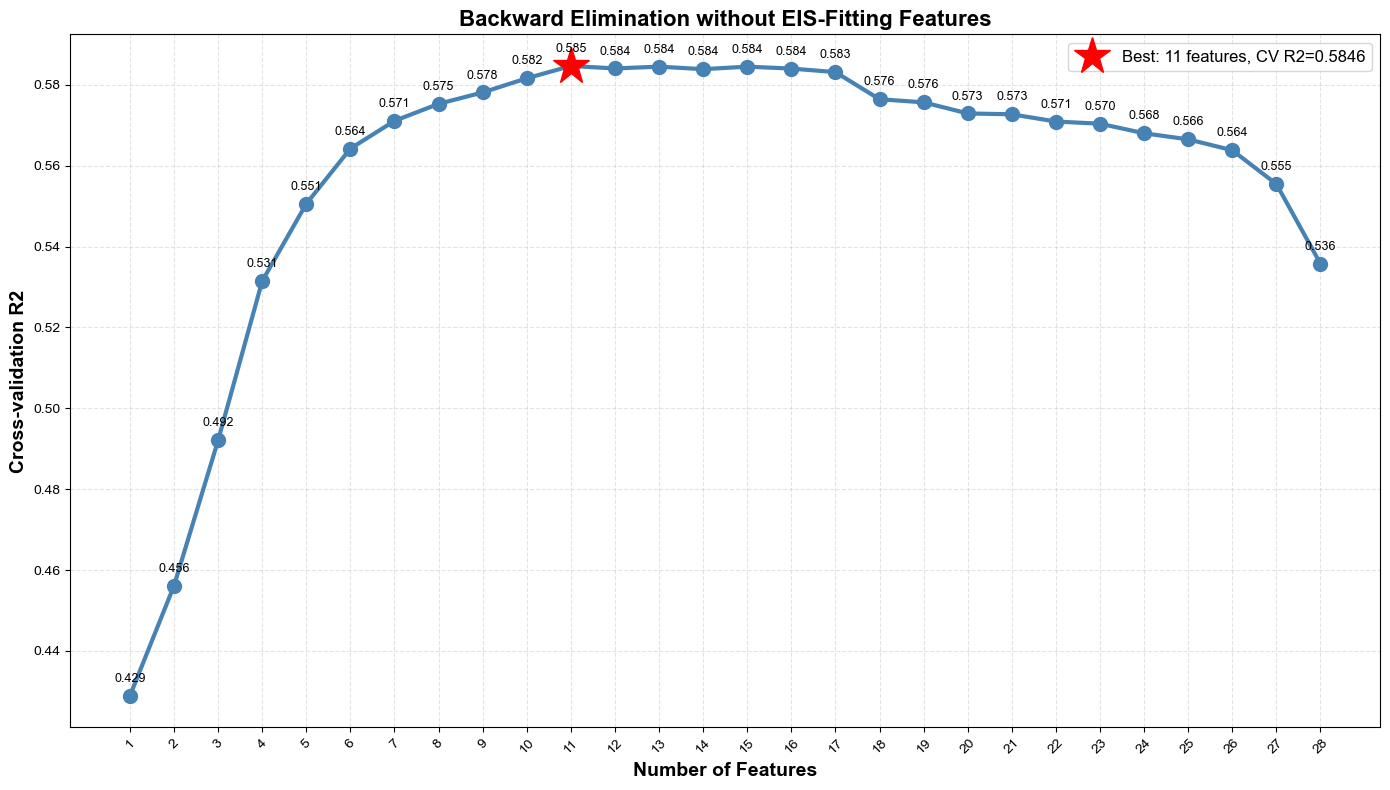


BEST FEATURE CONFIGURATION
Number of features: 11
CV R2: 0.5846
Features:
  1. I_raw
  2. work_function_element2
  3. MM_bond_element2
  4. E_std_element1
  5. FE_ads_avg_element1
  6. delta_EOH_element1
  7. delta_EOH_element2
  8. electronegativity_element1
  9. electronegativity_element2
  10. MH_bond_kJ_element2
  11. MD_bond_kJ_element1


In [5]:
y_bins = pd.qcut(y, q=10, labels=False, duplicates="drop")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_SEED,
    stratify=y_bins,
)

print(f"Data split: {X_train.shape[0]} train, {X_test.shape[0]} test")

elimination_history = manual_backward_elimination(X_train, y_train, min_features=1)
history_df = plot_elimination_curve(elimination_history)

best_idx = history_df["cv_r2"].idxmax()
best_config = history_df.loc[best_idx]
selected_features = best_config["features"]

print("\n" + "=" * 100)
print("BEST FEATURE CONFIGURATION")
print("=" * 100)
print(f"Number of features: {len(selected_features)}")
print(f"CV R2: {best_config['cv_r2']:.4f}")
print("Features:")
for i, feature in enumerate(selected_features, 1):
    print(f"  {i}. {feature}")

pd.DataFrame({"selected_feature": selected_features}).to_csv(OUTPUT_DIR / "selected_features.csv", index=False)


In [6]:
def train_models_with_selected_features(X_train, X_test, y_train, y_test, selected_features):
    print("\n" + "=" * 100)
    print("STEP 3: TRAIN MODELS WITH SELECTED FEATURES")
    print("=" * 100)

    X_train_sel = X_train[selected_features]
    X_test_sel = X_test[selected_features]

    models_config = {
        "Random Forest": {
            "model": RandomForestRegressor(random_state=RANDOM_SEED),
            "params": {
                "n_estimators": [100, 200],
                "max_depth": [10, 15, None],
                "min_samples_split": [2, 5],
                "min_samples_leaf": [1, 2],
            },
        },
        "Extra Trees": {
            "model": ExtraTreesRegressor(random_state=RANDOM_SEED),
            "params": {
                "n_estimators": [100, 200],
                "max_depth": [10, 15, None],
                "min_samples_split": [2, 5],
                "min_samples_leaf": [1, 2],
            },
        },
        "XGBoost": {
            "model": xgb.XGBRegressor(random_state=RANDOM_SEED),
            "params": {
                "n_estimators": [50, 100, 200],
                "max_depth": [3, 5, 7],
                "learning_rate": [0.05, 0.1],
                "subsample": [0.8, 1.0],
            },
        },
    }

    results = []
    best_model_info = None
    best_score = -np.inf

    for model_name, config in models_config.items():
        print(f"\n--- {model_name} ---")
        grid_search = GridSearchCV(config["model"], config["params"], cv=5, scoring="r2", n_jobs=-1, verbose=0)
        grid_search.fit(X_train_sel, y_train)
        model = grid_search.best_estimator_
        y_train_pred = model.predict(X_train_sel)
        y_test_pred = model.predict(X_test_sel)
        train_r2 = r2_score(y_train, y_train_pred)
        test_r2 = r2_score(y_test, y_test_pred)
        train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
        test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
        overfitting = train_r2 - test_r2
        print(f"Best params: {grid_search.best_params_}")
        print(f"Best CV score: {grid_search.best_score_:.4f}")
        print(f"Train R2: {train_r2:.4f}, RMSE: {train_rmse:.4f}")
        print(f"Test R2: {test_r2:.4f}, RMSE: {test_rmse:.4f}")
        print(f"Overfitting: {overfitting:.4f}")

        info = {
            "model_name": model_name,
            "best_params": grid_search.best_params_,
            "best_cv_score": grid_search.best_score_,
            "train_r2": train_r2,
            "test_r2": test_r2,
            "train_rmse": train_rmse,
            "test_rmse": test_rmse,
            "overfitting": overfitting,
            "model": model,
            "X_train": X_train_sel,
            "X_test": X_test_sel,
            "y_train": y_train,
            "y_test": y_test,
            "y_train_pred": y_train_pred,
            "y_test_pred": y_test_pred,
            "features": selected_features,
        }
        results.append(info)
        if test_r2 > best_score:
            best_score = test_r2
            best_model_info = info

    results_df = pd.DataFrame([
        {k: v for k, v in item.items() if k not in ["model", "X_train", "X_test", "y_train", "y_test", "y_train_pred", "y_test_pred", "features"]}
        for item in results
    ]).sort_values("test_r2", ascending=False)
    results_df.to_csv(OUTPUT_DIR / "final_model_results.csv", index=False)
    print("\nModel performance ranking:")
    print(results_df[["model_name", "best_cv_score", "test_r2", "test_rmse", "overfitting"]].to_string(index=False))
    return best_model_info, results_df


def plot_prediction(best_model):
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    ax = axes[0]
    ax.scatter(best_model["y_test"], best_model["y_test_pred"], alpha=0.65, s=50, color="orange", edgecolors="k", linewidth=0.5)
    min_val = min(best_model["y_test"].min(), best_model["y_test_pred"].min())
    max_val = max(best_model["y_test"].max(), best_model["y_test_pred"].max())
    ax.plot([min_val, max_val], [min_val, max_val], "r--", linewidth=2, label="Perfect prediction")
    ax.set_xlabel("Measured Separation Coefficient", fontsize=13, fontweight="bold")
    ax.set_ylabel("Predicted Separation Coefficient", fontsize=13, fontweight="bold")
    ax.set_title(f"Test Set\nR2 = {best_model['test_r2']:.4f}, RMSE = {best_model['test_rmse']:.4f}", fontsize=14, fontweight="bold")
    ax.legend(fontsize=11)
    ax.grid(alpha=0.3)
    ax.set_aspect("equal", adjustable="box")

    ax = axes[1]
    residuals = best_model["y_test"] - best_model["y_test_pred"]
    ax.scatter(best_model["y_test_pred"], residuals, alpha=0.65, s=50, color="orange", edgecolors="k", linewidth=0.5)
    ax.axhline(y=0, color="r", linestyle="--", linewidth=2)
    ax.set_xlabel("Predicted Separation Coefficient", fontsize=13, fontweight="bold")
    ax.set_ylabel("Residuals", fontsize=13, fontweight="bold")
    ax.set_title("Residual Plot", fontsize=14, fontweight="bold")
    ax.grid(alpha=0.3)

    fig.suptitle(f"{best_model['model_name']} - Selected Features", fontsize=16, fontweight="bold", y=0.98)
    plt.tight_layout()
    pred_file = OUTPUT_DIR / "prediction_selected_features.png"
    plt.savefig(pred_file, dpi=300, bbox_inches="tight")
    print(f"[OK] Prediction plot saved to: {pred_file}")
    plt.show()
    plt.close()


def map_feature_names(feature_name):
    feature_name = feature_name.replace("_", " ").title()
    feature_name = feature_name.replace("Element1", "(Element 1)").replace("Element2", "(Element 2)")
    feature_name = feature_name.replace("Rs From Eis", "Rs From EIS")
    feature_name = feature_name.replace("I Raw", "I Raw")
    feature_name = feature_name.replace("Fe Ads Avg", "Adsorption Energy of H")
    feature_name = feature_name.replace("Delta Eoh", "Adsorption Energy of OH")
    feature_name = feature_name.replace("Pzc", "Potential of Zero Charge")
    feature_name = feature_name.replace("Mm Bond", "M-M Bond Energy")
    feature_name = feature_name.replace("E Std", "Standard Potential")
    feature_name = feature_name.replace("Mh Bond Kj", "M-H Bond Energy")
    feature_name = feature_name.replace("Md Bond Kj", "M-D Bond Energy")
    feature_name = feature_name.replace("Frequency", "Frequency of")
    feature_name = feature_name.replace("Oh", "OH")
    feature_name = feature_name.replace("Zpe H", "ZPE for H")
    return feature_name


def perform_shap_analysis(best_model, X_all_selected):
    shap_dir = OUTPUT_DIR / "shap_selected_features"
    if shap_dir.exists():
        shutil.rmtree(shap_dir)
    shap_dir.mkdir(parents=True, exist_ok=True)

    model = best_model["model"]
    explainer = shap.TreeExplainer(model)
    mapped_features = [map_feature_names(f) for f in best_model["features"]]

    def save_pair(X_values, label, suffix):
        X_values = X_values.copy().apply(pd.to_numeric, errors="coerce")
        shap_values = explainer.shap_values(X_values)
        n_samples = X_values.shape[0]
        print(f"SHAP dataset: {label} (n={n_samples})")

        plt.figure(figsize=(14, 10))
        shap.summary_plot(shap_values, X_values, feature_names=mapped_features, show=False)
        plt.title(f"SHAP summary ({label}, n={n_samples})", fontsize=16, fontweight="bold")
        plt.tight_layout()
        plt.savefig(shap_dir / f"shap_swarm_{suffix}.png", dpi=300, bbox_inches="tight")
        plt.show()
        plt.close()

        plt.figure(figsize=(14, 10))
        shap.summary_plot(shap_values, X_values, feature_names=mapped_features, plot_type="bar", show=False)
        plt.title(f"Mean absolute SHAP value ({label}, n={n_samples})", fontsize=16, fontweight="bold")
        plt.tight_layout()
        plt.savefig(shap_dir / f"shap_bar_{suffix}.png", dpi=300, bbox_inches="tight")
        plt.show()
        plt.close()

    save_pair(best_model["X_test"], "held-out test set", "test_set")
    save_pair(X_all_selected, "all no-BO samples", "all_samples")



STEP 3: TRAIN MODELS WITH SELECTED FEATURES

--- Random Forest ---


Best params: {'max_depth': 15, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}
Best CV score: 0.5863
Train R2: 0.8991, RMSE: 0.5293
Test R2: 0.6336, RMSE: 0.9863
Overfitting: 0.2656

--- Extra Trees ---


Best params: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 200}
Best CV score: 0.5578
Train R2: 0.9109, RMSE: 0.4974
Test R2: 0.6317, RMSE: 0.9887
Overfitting: 0.2792

--- XGBoost ---


Best params: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 100, 'subsample': 0.8}
Best CV score: 0.5686
Train R2: 0.9008, RMSE: 0.5248
Test R2: 0.6346, RMSE: 0.9849
Overfitting: 0.2662

Model performance ranking:
   model_name  best_cv_score  test_r2  test_rmse  overfitting
      XGBoost       0.568561 0.634579   0.984899     0.266234
Random Forest       0.586313 0.633551   0.986283     0.265573
  Extra Trees       0.557842 0.631734   0.988726     0.279178


[OK] Prediction plot saved to: outputs\feature_selection_561_rs_from_eis_no_eis_fitting_seed42\prediction_selected_features.png


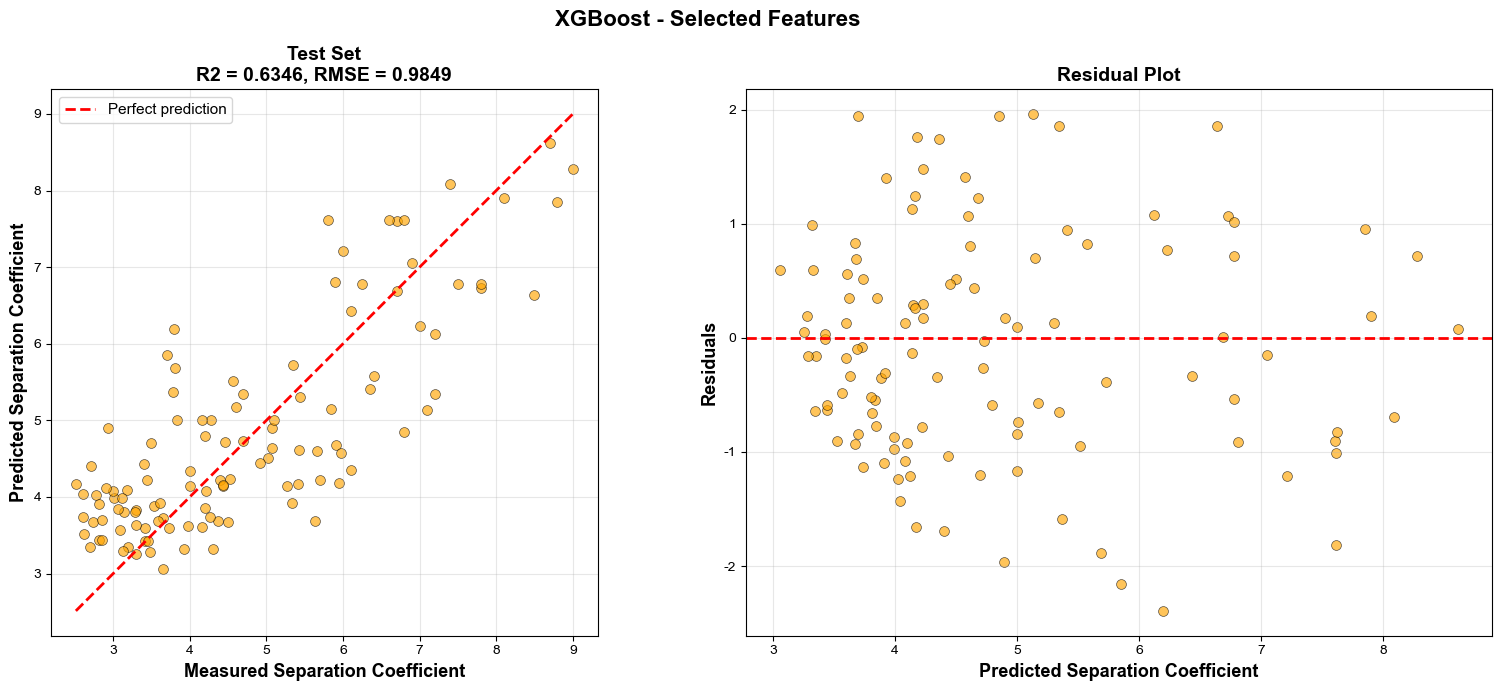

SHAP dataset: held-out test set (n=113)


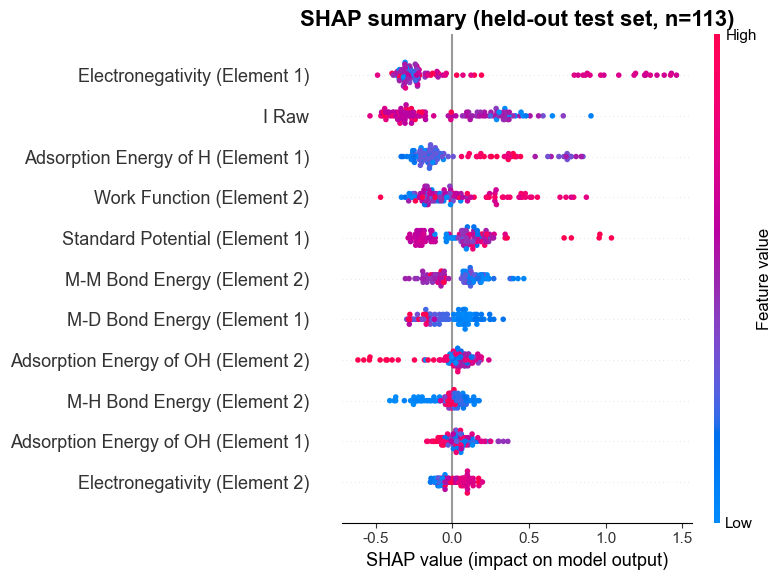

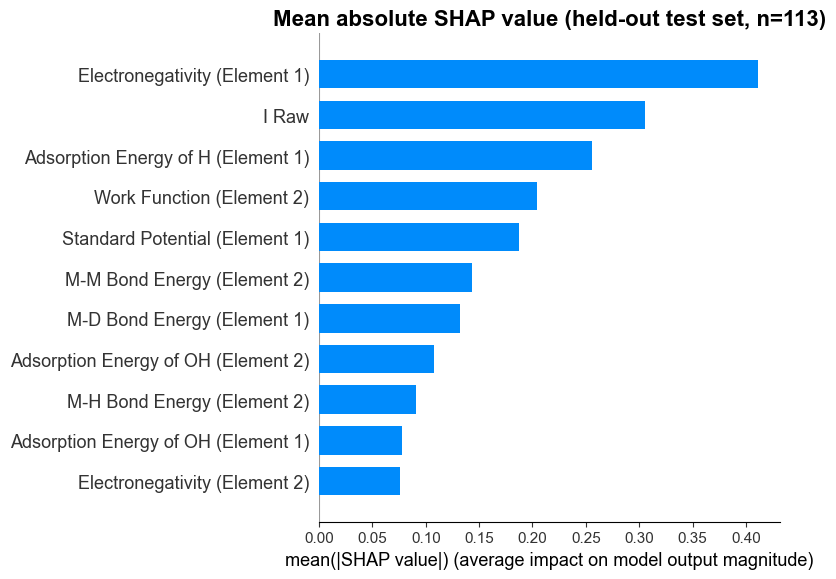

SHAP dataset: all no-BO samples (n=561)


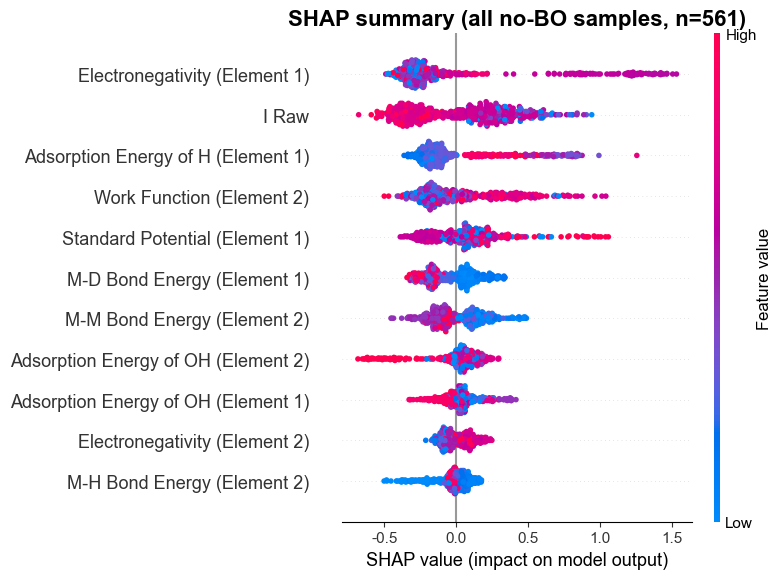

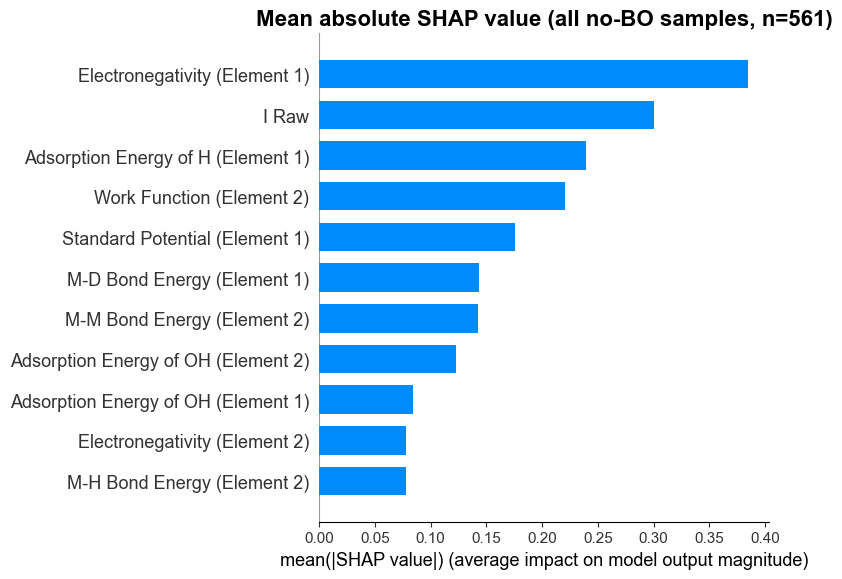


FINAL SUMMARY
Best model: XGBoost
Number of selected features: 11
Test R2: 0.6346
Test RMSE: 0.9849
Selected features:
  1. I_raw
  2. work_function_element2
  3. MM_bond_element2
  4. E_std_element1
  5. FE_ads_avg_element1
  6. delta_EOH_element1
  7. delta_EOH_element2
  8. electronegativity_element1
  9. electronegativity_element2
  10. MH_bond_kJ_element2
  11. MD_bond_kJ_element1
Outputs saved to: outputs\feature_selection_561_rs_from_eis_no_eis_fitting_seed42


In [7]:
best_model, results_df = train_models_with_selected_features(
    X_train,
    X_test,
    y_train,
    y_test,
    selected_features,
)

plot_prediction(best_model)
perform_shap_analysis(best_model, X[selected_features])

print("\n" + "=" * 100)
print("FINAL SUMMARY")
print("=" * 100)
print(f"Best model: {best_model['model_name']}")
print(f"Number of selected features: {len(selected_features)}")
print(f"Test R2: {best_model['test_r2']:.4f}")
print(f"Test RMSE: {best_model['test_rmse']:.4f}")
print("Selected features:")
for i, feat in enumerate(selected_features, 1):
    print(f"  {i}. {feat}")
print(f"Outputs saved to: {OUTPUT_DIR}")
